# Phase 3 - Can an extra FFT step improve SEN2SR?

What we know so far:
- **Phase 0:** SEN2SR already ends with an FFT step: a Gaussian mask (σ = 35) takes low frequencies from bicubic and high frequencies from the CNN. So our idea must be something **different**.
- **Phase 2:** SEN2SR beats bicubic by only +0.03 dB PSNR, and adds only a little detail.

Plan:
1. **Diagnose** with the FFT on the train images: where are the errors? Is SEN2SR's fine detail too weak? Is it in the right place?
2. **Design** a refinement based on what we find: a gain per frequency, learned on the train split
3. **Evaluate** on the validation split with criteria written down **before** looking at the results
4. Keep it or drop it

(The test split is still not used.)

In [1]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
import mlstac
import rasterio
from skimage.metrics import structural_similarity

device = "mps" if torch.backends.mps.is_available() else "cpu"
print("device:", device)

device: mps


Same helpers as in Phase 2 (copied): loading, SEN2SR, bicubic and the metrics.

In [2]:
data_dir = "sen2naip/cross-sensor"
band_names = ["R", "G", "B", "NIR"]

index = pd.read_csv("dataset_index.csv")
train = index[index["split"] == "train"].reset_index(drop=True)
val = index[index["split"] == "val"].reset_index(drop=True)
print("train:", len(train), "| val:", len(val))

def load_pair(row):
    with rasterio.open(os.path.join(data_dir, row["folder"], "lr.tif")) as f:
        lr = np.clip(f.read().astype(np.float32) / 10000, 0, None)
    with rasterio.open(os.path.join(data_dir, row["folder"], "hr.tif")) as f:
        hr = f.read().astype(np.float32)
    for b, band in enumerate(band_names):
        hr[b] = row["a_" + band] * hr[b] + row["b_" + band]
    return lr, np.clip(hr, 0, None)

model = mlstac.load("model/SEN2SRLite_RGBN_x4").compiled_model(device=device)

def super_resolve(lr):
    x = torch.from_numpy(lr).unsqueeze(0)
    x = F.pad(x, (0, 7, 0, 7), mode="replicate")          # 121 -> 128
    with torch.no_grad():
        out = model(x.to(device)).cpu()
    return out[0, :, :484, :484].numpy()

def bicubic(lr):
    up = F.interpolate(torch.from_numpy(lr).unsqueeze(0), scale_factor=4, mode="bicubic")
    return up[0].clamp(min=0).numpy()

border = 8
def crop(img):
    return img[:, border:-border, border:-border]

def psnr(pred, target):
    return 10 * np.log10(1.0 / np.mean((pred - target) ** 2))

def ssim(pred, target):
    return structural_similarity(target, pred, data_range=1.0, channel_axis=0)

def sam(pred, target):
    pred, target = pred.astype(np.float64), target.astype(np.float64)
    dot = np.sum(pred * target, axis=0)
    norms = np.linalg.norm(pred, axis=0) * np.linalg.norm(target, axis=0)
    valid = norms > 0
    return np.degrees(np.arccos(np.clip(dot[valid] / norms[valid], -1, 1))).mean()

def lr_consistency(pred, lr):
    small = pred.reshape(4, 121, 4, 121, 4).mean(axis=(2, 4))
    return psnr(small, lr)

train: 1999 | val: 433


## 1. What does an image look like in the frequency domain?

The 2D FFT turns an image into frequencies. After `fftshift` the **centre** is the lowest frequency (big smooth areas) and the **edges** are the highest frequencies (sharp edges, fine texture). We plot log(|FFT|) because the values cover a huge range.

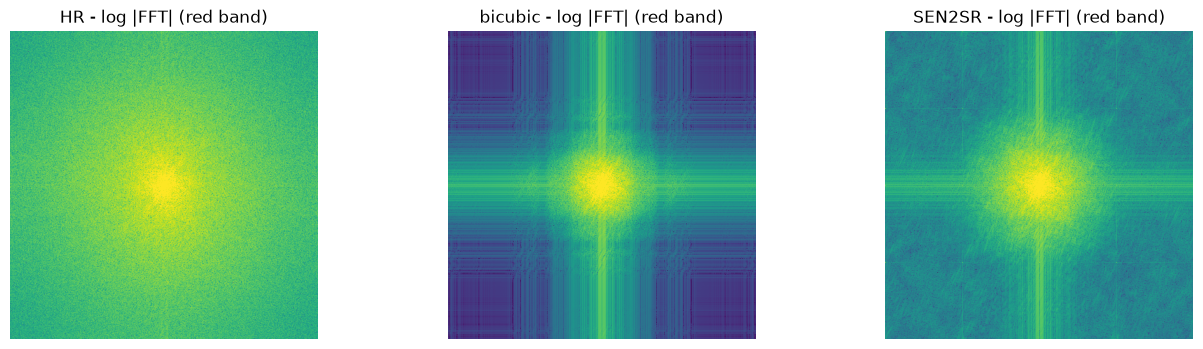

In [3]:
lr, hr = load_pair(val.iloc[0])
sr = super_resolve(lr)
bic = bicubic(lr)

plt.figure(figsize=(16, 4))
for k, (name, img) in enumerate([("HR", hr), ("bicubic", bic), ("SEN2SR", sr)]):
    spectrum = np.fft.fftshift(np.fft.fft2(img[0]))          # red band
    plt.subplot(1, 3, k + 1)
    plt.imshow(np.log(np.abs(spectrum) + 1e-6), cmap="viridis", vmin=-8, vmax=4)
    plt.title(f"{name} - log |FFT| (red band)")
    plt.axis("off")
plt.show()

HR has energy everywhere (fine details). Bicubic's spectrum is a small bright square in the middle - it has almost nothing at high frequencies. SEN2SR is in between.

To compare many images, we average the spectrum over **rings** around the centre: every ring is one frequency. Frequency is measured in cycles per HR pixel:
- 0 = constant, 0.5 = the finest possible pattern (1 pixel on, 1 pixel off)
- **0.125 = LR Nyquist**: the finest detail a 10 m image can contain (1 LR pixel = 4 HR pixels → 1/8 cycles per HR pixel). Everything above 0.125 has to be "invented" by the super-resolution.

FFT grid: (484, 484) | number of rings: 71 | max frequency: 0.707


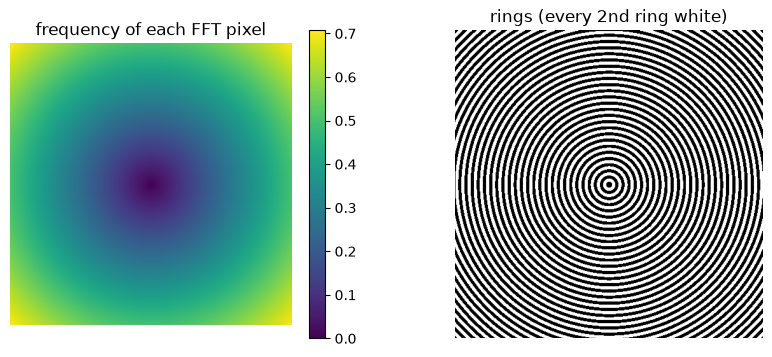

In [4]:
N = 484
fy = np.fft.fftfreq(N)[:, None]
fx = np.fft.fftfreq(N)[None, :]
freq = np.sqrt(fx ** 2 + fy ** 2)              # frequency of every FFT pixel (cycles / HR pixel)

ring_width = 0.01
ring = (freq / ring_width).astype(int)         # ring number of every FFT pixel
n_rings = ring.max() + 1
ring_freq = (np.arange(n_rings) + 0.5) * ring_width
nyquist = 0.125

print("FFT grid:", freq.shape, "| number of rings:", n_rings, "| max frequency:", freq.max().round(3))

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1); plt.imshow(np.fft.fftshift(freq)); plt.colorbar(); plt.title("frequency of each FFT pixel"); plt.axis("off")
plt.subplot(1, 2, 2); plt.imshow(np.fft.fftshift(ring) % 2, cmap="gray"); plt.title("rings (every 2nd ring white)"); plt.axis("off")
plt.show()

def ring_sum(x):
    # x: (4, N, N) -> (4, n_rings): sum of x over every ring, per band
    return np.stack([np.bincount(ring.ravel(), weights=x[b].ravel(), minlength=n_rings) for b in range(4)])

## 2. Diagnosis on the train images

For every train image we compute the FFT of HR (H), bicubic (Bc) and SEN2SR (S) and add up per ring:
- power of HR, bicubic, SEN2SR: |H|², |Bc|², |S|²
- power of the error: |S − H|²
- the "agreement" between SEN2SR and HR: Re(S · conj(H)). Large and positive when SEN2SR's detail is in the same place as HR's detail.

In [5]:
power_hr = np.zeros((4, n_rings))
power_bic = np.zeros((4, n_rings))
power_sr = np.zeros((4, n_rings))
power_err = np.zeros((4, n_rings))
agreement = np.zeros((4, n_rings))

start = time.time()
for i, row in train.iterrows():
    lr, hr = load_pair(row)
    H = np.fft.fft2(hr)
    S = np.fft.fft2(super_resolve(lr))
    Bc = np.fft.fft2(bicubic(lr))

    power_hr += ring_sum(np.abs(H) ** 2)
    power_bic += ring_sum(np.abs(Bc) ** 2)
    power_sr += ring_sum(np.abs(S) ** 2)
    power_err += ring_sum(np.abs(S - H) ** 2)
    agreement += ring_sum(np.real(S * np.conj(H)))

    if i % 500 == 0:
        print(i, "/", len(train))

print(f"done in {time.time() - start:.0f} s")

0 / 1999
500 / 1999
1000 / 1999
1500 / 1999
done in 152 s


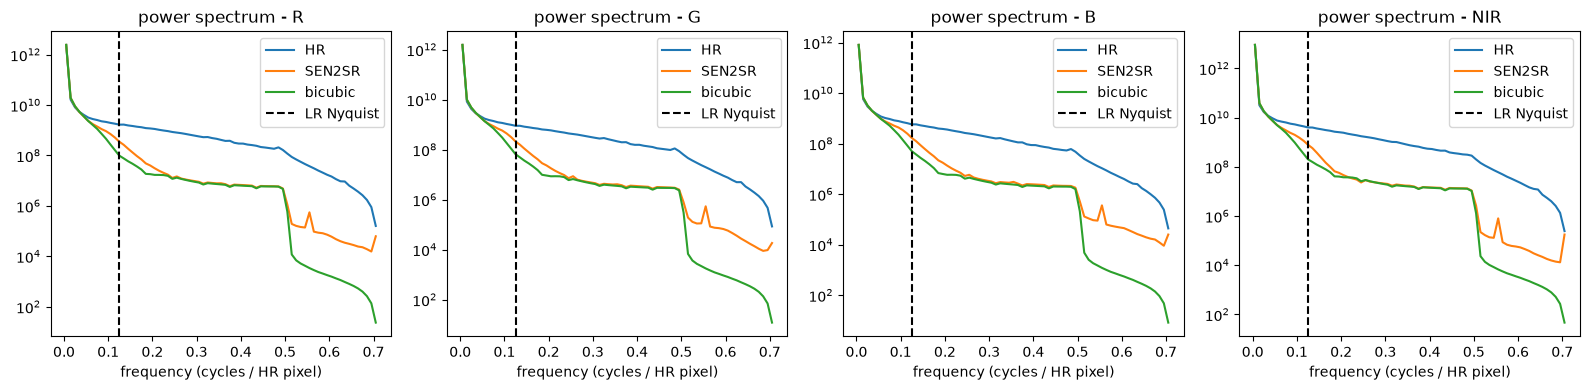

In [6]:
mask_sigma = 35 / 512                          # SEN2SR's Gaussian mask in cycles per pixel
sen2sr_mask = np.exp(-ring_freq ** 2 / (2 * mask_sigma ** 2))

plt.figure(figsize=(16, 4))
for b in range(4):
    plt.subplot(1, 4, b + 1)
    plt.semilogy(ring_freq, power_hr[b], label="HR")
    plt.semilogy(ring_freq, power_sr[b], label="SEN2SR")
    plt.semilogy(ring_freq, power_bic[b], label="bicubic")
    plt.axvline(nyquist, color="k", linestyle="--", label="LR Nyquist")
    plt.xlabel("frequency (cycles / HR pixel)")
    plt.title(f"power spectrum - {band_names[b]}")
    plt.legend()
plt.tight_layout()
plt.show()

Easier to read as a **ratio**: how much of HR's power does each method have at each frequency? (1 = same as HR)

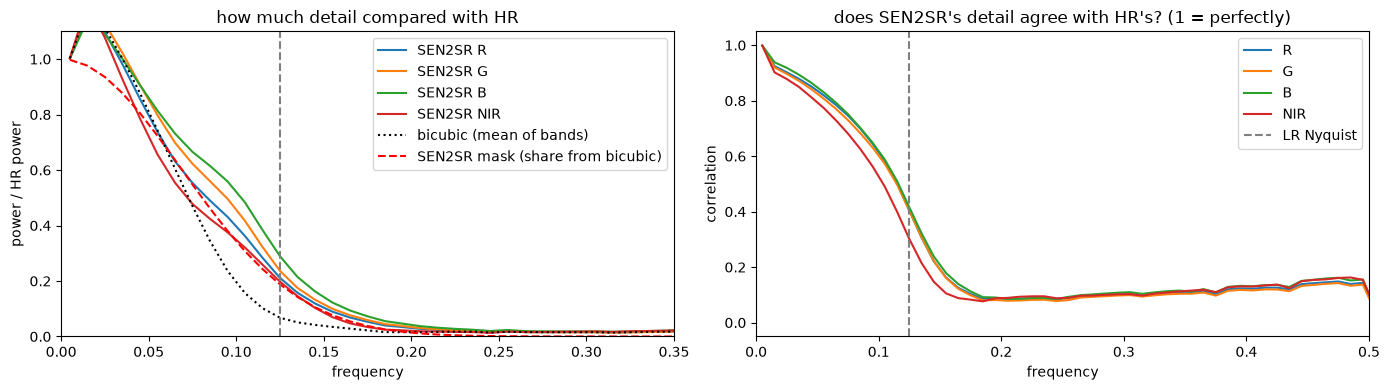

f = 0.065: SEN2SR has  65.4% of HR power (bicubic 60.5%), correlation with HR 0.77
f = 0.095: SEN2SR has  46.6% of HR power (bicubic 23.7%), correlation with HR 0.62
f = 0.155: SEN2SR has   9.5% of HR power (bicubic  3.5%), correlation with HR 0.15
f = 0.205: SEN2SR has   2.9% of HR power (bicubic  1.5%), correlation with HR 0.08
f = 0.305: SEN2SR has   1.7% of HR power (bicubic  1.6%), correlation with HR 0.10


In [7]:
ratio_sr = power_sr / power_hr
ratio_bic = power_bic / power_hr

plt.figure(figsize=(14, 4))
plt.subplot(1, 2, 1)
for b in range(4):
    plt.plot(ring_freq, ratio_sr[b], label=f"SEN2SR {band_names[b]}")
plt.plot(ring_freq, ratio_bic.mean(0), "k:", label="bicubic (mean of bands)")
plt.plot(ring_freq, sen2sr_mask, "r--", label="SEN2SR mask (share from bicubic)")
plt.axvline(nyquist, color="gray", linestyle="--")
plt.xlim(0, 0.35); plt.ylim(0, 1.1)
plt.xlabel("frequency"); plt.ylabel("power / HR power"); plt.title("how much detail compared with HR")
plt.legend()

coherence = agreement / np.sqrt(power_sr * power_hr)
plt.subplot(1, 2, 2)
for b in range(4):
    plt.plot(ring_freq, coherence[b], label=band_names[b])
plt.axvline(nyquist, color="gray", linestyle="--", label="LR Nyquist")
plt.xlim(0, 0.5); plt.ylim(-0.05, 1.05)
plt.xlabel("frequency"); plt.ylabel("correlation"); plt.title("does SEN2SR's detail agree with HR's? (1 = perfectly)")
plt.legend()
plt.tight_layout()
plt.show()

for f in [0.065, 0.095, 0.155, 0.205, 0.305]:
    r = int(f / ring_width)
    print(f"f = {f:.3f}: SEN2SR has {ratio_sr[:, r].mean() * 100:5.1f}% of HR power (bicubic {ratio_bic[:, r].mean() * 100:4.1f}%), correlation with HR {coherence[:, r].mean():.2f}")

Where is the error? Share of the total error power below / above the LR Nyquist:

R    error below Nyquist: 45.1%   (in the lowest ring alone: 13.7%)   above: 54.9%
G    error below Nyquist: 46.6%   (in the lowest ring alone: 13.8%)   above: 53.4%
B    error below Nyquist: 45.5%   (in the lowest ring alone: 12.4%)   above: 54.5%
NIR  error below Nyquist: 53.0%   (in the lowest ring alone: 17.6%)   above: 47.0%


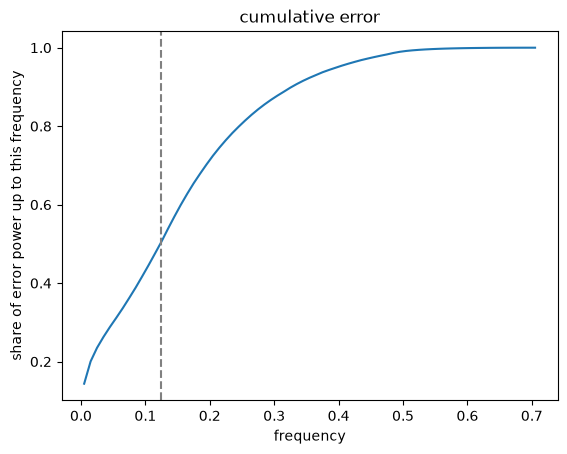

In [8]:
error_share = power_err / power_err.sum(axis=1, keepdims=True)
below = error_share[:, ring_freq < nyquist].sum(axis=1)
lowest = error_share[:, 0]

for b in range(4):
    print(f"{band_names[b]:4s} error below Nyquist: {below[b] * 100:4.1f}%   (in the lowest ring alone: {lowest[b] * 100:4.1f}%)   above: {(1 - below[b]) * 100:4.1f}%")

plt.plot(ring_freq, np.cumsum(error_share.mean(0)))
plt.axvline(nyquist, color="gray", linestyle="--")
plt.xlabel("frequency"); plt.ylabel("share of error power up to this frequency")
plt.title("cumulative error")
plt.show()

**What the diagnosis says:**
1. **SEN2SR's fine detail is too weak.** Above the LR Nyquist it has only around 10% of HR's power at first, dropping to a few % (bicubic has even less).
2. **And the detail it adds mostly does not agree with HR.** The correlation drops from ~0.8 to ~0.1-0.2 above the Nyquist. Some of SEN2SR's edges are in the right place, most are not exactly (also because LR and HR are slightly shifted in this dataset).
3. **About half of the error is below the Nyquist**, a big part in the lowest ring. These are large-scale brightness differences between the two sensors (Sentinel-2 vs NAIP). No super-resolution method can fix these, and SEN2SR's mask deliberately takes those frequencies from the LR.

So there are two things one could try with a gain per frequency:
- **boost** SEN2SR's detail, because it is too weak (point 1)
- **damp** it, because most of it is in the wrong place (point 2)

These pull in opposite directions. Let's try both.

## 3. The refinement: a gain per frequency

```
refined = IFFT( FFT(SEN2SR) × G(frequency) )
```
with G = 1 (no change) at and below the LR Nyquist. So we only touch the frequencies the 10 m image cannot contain. Everything SEN2SR's own FFT constraint controls (low frequencies from the satellite) stays as it is.

This is different from SEN2SR's mask: the mask decides **who** provides each frequency (bicubic or CNN, fixed). Our G decides **how strong** the CNN's detail should be at each frequency, learned from our real image pairs. One G curve per band, learned on **train**.

Two ways to choose G:
- **A. PSNR-optimal:** the number per ring that makes the result closest to HR (least squares). Formula: G = Σ Re(S · conj(H)) / Σ |S|²
- **B. Spectrum matching:** make SEN2SR's power equal to HR's power (sharper). G = sqrt(HR power / SEN2SR power), capped at 3 so noise is not blown up.

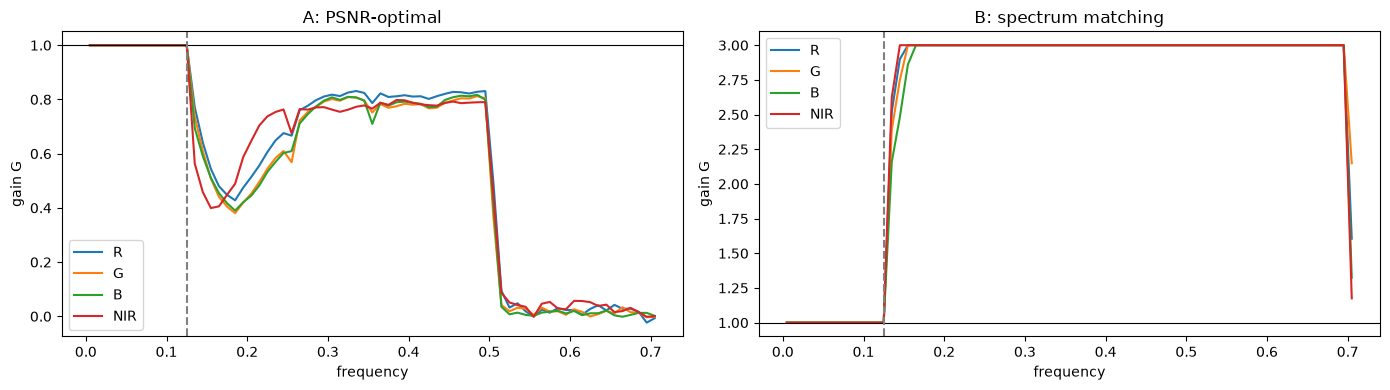

at f = 0.155 (red band):
  gain A: 0.543 | gain B: 3.0
  check: gain A = correlation x sqrt(HR power / SEN2SR power) = 0.162 x 3.347 = 0.543


In [9]:
above = ring_freq > nyquist

gain_a = np.where(above, agreement / power_sr, 1.0)
gain_b = np.where(above, np.clip(np.sqrt(power_hr / power_sr), 1, 3), 1.0)

plt.figure(figsize=(14, 4))
for k, (name, g) in enumerate([("A: PSNR-optimal", gain_a), ("B: spectrum matching", gain_b)]):
    plt.subplot(1, 2, k + 1)
    for b in range(4):
        plt.plot(ring_freq, g[b], label=band_names[b])
    plt.axhline(1, color="k", linewidth=0.8)
    plt.axvline(nyquist, color="gray", linestyle="--")
    plt.xlabel("frequency"); plt.ylabel("gain G"); plt.title(name); plt.legend()
plt.tight_layout()
plt.show()

r = int(0.155 / ring_width)
print("at f = 0.155 (red band):")
print("  gain A:", gain_a[0, r].round(3), "| gain B:", gain_b[0, r].round(3))
print("  check: gain A = correlation x sqrt(HR power / SEN2SR power) =",
      round(coherence[0, r], 3), "x", round(np.sqrt(power_hr[0, r] / power_sr[0, r]), 3), "=",
      round(coherence[0, r] * np.sqrt(power_hr[0, r] / power_sr[0, r]), 3))

Gain A is **below 1**: the PSNR-optimal choice is to **damp** SEN2SR's detail. The check shows why: G_A = correlation × sqrt(power ratio). "Too weak" says multiply by ~3, but "mostly in the wrong place" says multiply by ~0.15, and together that is ~0.5.

Gain B boosts everything (up to the cap of 3).

(Above f = 0.5 there are only the corners of the FFT grid, where there is almost no energy, so G there does not matter much.)

Try both on one validation image:

shapes: (4, 484, 484) (4, 484, 484) (4, 484, 484)
SEN2SR               PSNR 30.922  SAM 3.588  LR consistency 59.10
A (PSNR-optimal)     PSNR 30.931  SAM 3.576  LR consistency 60.53
B (spectrum match)   PSNR 30.769  SAM 3.726  LR consistency 48.46


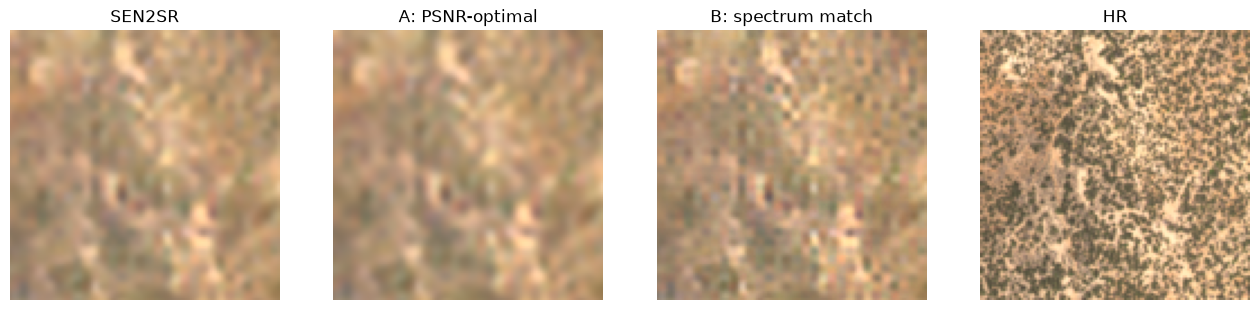

In [10]:
def refine(sr, gain):
    G = np.stack([gain[b][ring] for b in range(4)])            # gain value for every FFT pixel
    out = np.real(np.fft.ifft2(np.fft.fft2(sr) * G))
    return np.clip(out, 0, None)

lr, hr = load_pair(val.iloc[5])
sr = super_resolve(lr)
sr_a, sr_b = refine(sr, gain_a), refine(sr, gain_b)
print("shapes:", sr.shape, sr_a.shape, sr_b.shape)

for name, img in [("SEN2SR", sr), ("A (PSNR-optimal)", sr_a), ("B (spectrum match)", sr_b)]:
    print(f"{name:20s} PSNR {psnr(crop(img), crop(hr)):.3f}  SAM {sam(crop(img), crop(hr)):.3f}  LR consistency {lr_consistency(img, lr):.2f}")

stretch = np.percentile(hr[:3], 99)
z = lambda img: np.clip(img[:3, 200:320, 200:320].transpose(1, 2, 0) / stretch, 0, 1)
plt.figure(figsize=(16, 4.5))
for k, (name, img) in enumerate([("SEN2SR", sr), ("A: PSNR-optimal", sr_a), ("B: spectrum match", sr_b), ("HR", hr)]):
    plt.subplot(1, 4, k + 1); plt.imshow(z(img)); plt.title(name); plt.axis("off")
plt.show()

## 4. Evaluation on the validation split

**Decision rule, written down before running it.** A refinement is kept only if, compared with plain SEN2SR on the 433 validation images:
1. PSNR improves and the 95% bootstrap CI of the difference is above 0
2. SSIM does not get worse (CI not entirely below 0)
3. SAM does not get worse (CI not entirely above 0)
4. LR consistency does not get worse
5. It does **not** remove detail: high-frequency power (above the Nyquist) must stay at least at SEN2SR's level. Otherwise the "improvement" is just blurring, which is the opposite of super-resolution.

To measure point 5: **HF ratio** = power above the Nyquist / HR's power above the Nyquist (1 = as much fine detail as HR).

In [11]:
def hf_ratio(pred, hr):
    P = np.abs(np.fft.fft2(pred)) ** 2
    Q = np.abs(np.fft.fft2(hr)) ** 2
    return P[:, freq > nyquist].sum() / Q[:, freq > nyquist].sum()

rows = []
start = time.time()
for i, row in val.iterrows():
    lr, hr = load_pair(row)
    sr = super_resolve(lr)
    outputs = {"bicubic": bicubic(lr), "sen2sr": sr, "fft_A": refine(sr, gain_a), "fft_B": refine(sr, gain_b)}
    for method, pred in outputs.items():
        rows.append({"folder": row["folder"], "method": method, "low_fit": row["low_fit"],
                     "psnr": psnr(crop(pred), crop(hr)), "ssim": ssim(crop(pred), crop(hr)),
                     "sam": sam(crop(pred), crop(hr)), "lr_consistency": lr_consistency(pred, lr),
                     "hf_ratio": hf_ratio(pred, hr)})
    if i % 100 == 0:
        print(i, "/", len(val))

results = pd.DataFrame(rows)
print(f"done in {time.time() - start:.0f} s", results.shape)

metrics = ["psnr", "ssim", "sam", "lr_consistency", "hf_ratio"]
results.groupby("method")[metrics].mean().loc[["bicubic", "sen2sr", "fft_A", "fft_B"]].round(4)

0 / 433
100 / 433
200 / 433
300 / 433
400 / 433
done in 120 s (1732, 8)


,psnr,ssim,sam,lr_consistency,hf_ratio
method,,,,,
bicubic,34.2839,0.8454,2.1803,57.1970,0.0387
sen2sr,34.3134,0.8489,2.1753,59.3405,0.0776
fft_A,34.3336,0.8493,2.1662,60.9372,0.0346
fft_B,33.9747,0.8378,2.3309,48.1304,0.5554


In [12]:
def bootstrap_ci(values, n=2000, seed=0):
    rng = np.random.default_rng(seed)
    means = [rng.choice(values, size=len(values), replace=True).mean() for _ in range(n)]
    return np.percentile(means, 2.5), np.percentile(means, 97.5)

base = results[results["method"] == "sen2sr"].set_index("folder")
decision = {}

for method in ["fft_A", "fft_B"]:
    other = results[results["method"] == method].set_index("folder")
    print(f"--- {method} minus SEN2SR ---")
    ci = {}
    for m in metrics:
        diff = (other[m] - base[m]).values
        ci[m] = bootstrap_ci(diff)
        print(f"{m:15s} mean {diff.mean():+.4f}   95% CI [{ci[m][0]:+.4f}, {ci[m][1]:+.4f}]")
    checks = {
        "1 PSNR better": ci["psnr"][0] > 0,
        "2 SSIM not worse": ci["ssim"][1] >= 0,
        "3 SAM not worse": ci["sam"][0] <= 0,
        "4 LR consistency not worse": ci["lr_consistency"][1] >= 0,
        "5 keeps the detail": other["hf_ratio"].mean() >= base["hf_ratio"].mean(),
    }
    for name, ok in checks.items():
        print("   ", "PASS" if ok else "FAIL", name)
    decision[method] = all(checks.values())
    print("   KEEP" if decision[method] else "   DROP")
    print()

--- fft_A minus SEN2SR ---
psnr            mean +0.0202   95% CI [+0.0181, +0.0225]
ssim            mean +0.0004   95% CI [+0.0003, +0.0004]
sam             mean -0.0091   95% CI [-0.0099, -0.0083]
lr_consistency  mean +1.5966   95% CI [+1.4811, +1.7093]
hf_ratio        mean -0.0430   95% CI [-0.0494, -0.0380]
    PASS 1 PSNR better
    PASS 2 SSIM not worse
    PASS 3 SAM not worse
    PASS 4 LR consistency not worse
    FAIL 5 keeps the detail
   DROP

--- fft_B minus SEN2SR ---
psnr            mean -0.3387   95% CI [-0.3545, -0.3230]
ssim            mean -0.0112   95% CI [-0.0117, -0.0106]
sam             mean +0.1556   95% CI [+0.1486, +0.1630]
lr_consistency  mean -11.2101   95% CI [-11.2945, -11.1343]
hf_ratio        mean +0.4778   95% CI [+0.4247, +0.5463]
    FAIL 1 PSNR better
    FAIL 2 SSIM not worse
    FAIL 3 SAM not worse
    FAIL 4 LR consistency not worse
    PASS 5 keeps the detail
   DROP



Visual check on three validation images (zoomed):

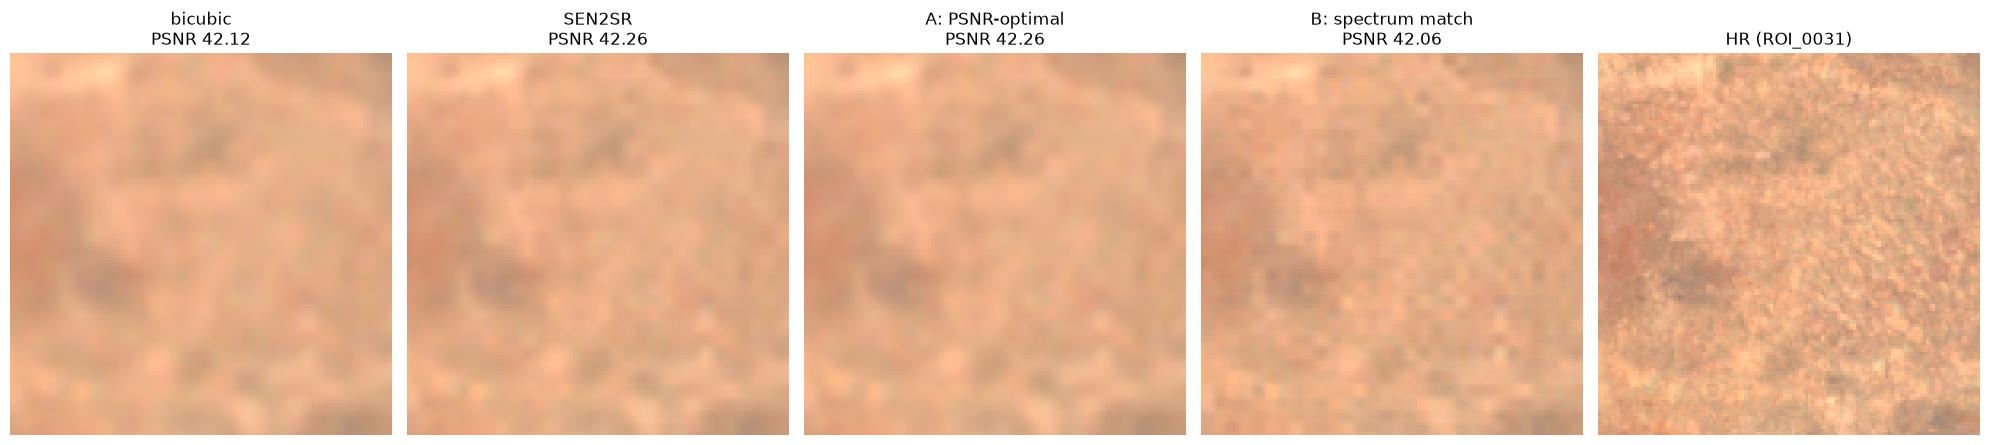

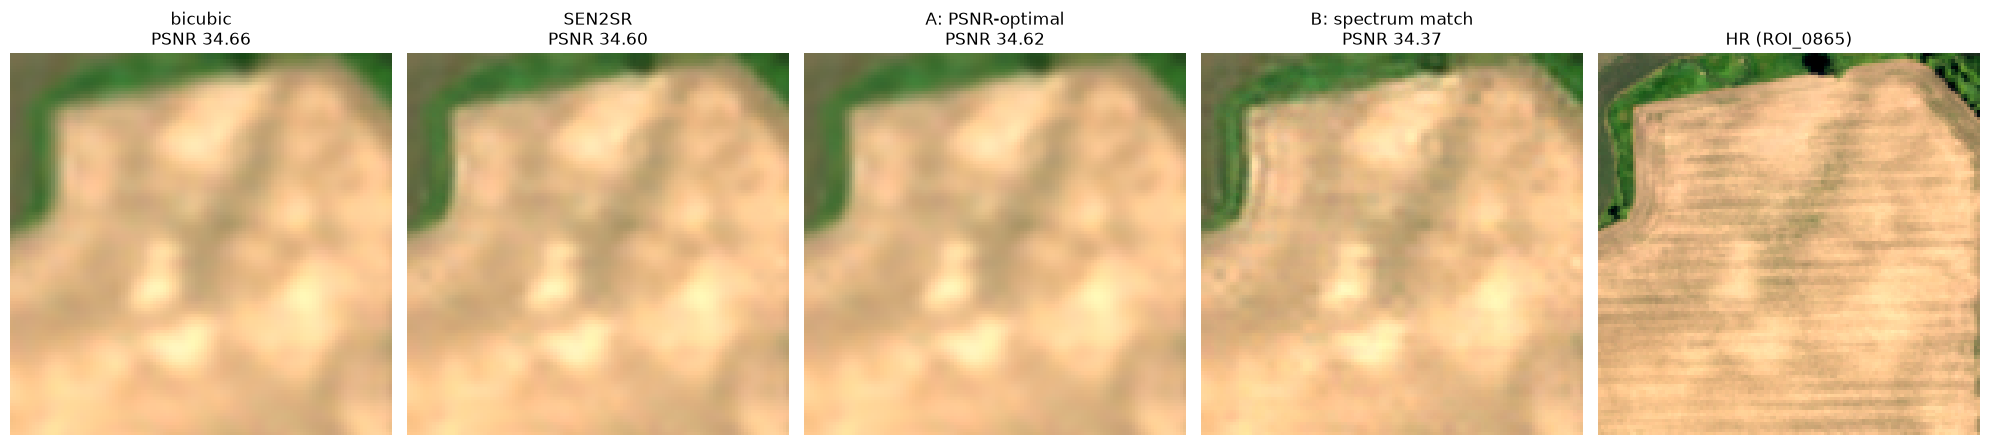

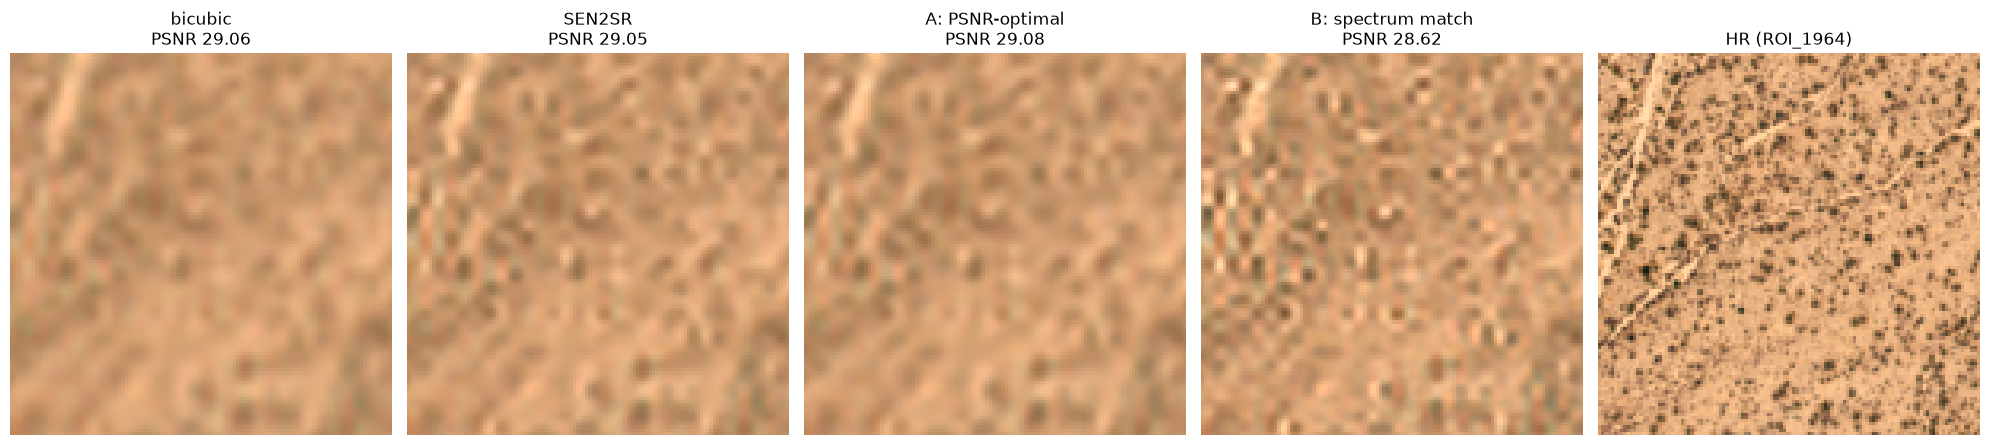

In [13]:
for folder in [val.iloc[10]["folder"], val.iloc[150]["folder"], val.iloc[300]["folder"]]:
    row = val[val["folder"] == folder].iloc[0]
    lr, hr = load_pair(row)
    sr = super_resolve(lr)
    images = [("bicubic", bicubic(lr)), ("SEN2SR", sr), ("A: PSNR-optimal", refine(sr, gain_a)),
              ("B: spectrum match", refine(sr, gain_b)), ("HR", hr)]
    stretch = np.percentile(hr[:3], 99)
    plt.figure(figsize=(20, 4.5))
    for k, (name, img) in enumerate(images):
        plt.subplot(1, 5, k + 1)
        plt.imshow(np.clip(img[:3, 180:300, 180:300].transpose(1, 2, 0) / stretch, 0, 1))
        if name == "HR":
            plt.title(f"HR ({folder})")
        else:
            plt.title(f"{name}\nPSNR {psnr(crop(img), crop(hr)):.2f}")
        plt.axis("off")
    plt.tight_layout()
    plt.show()

## 5. Save

In [14]:
results.to_csv("phase3_val_results.csv", index=False)

gains = pd.DataFrame({"frequency": np.repeat(ring_freq[None], 4, axis=0).ravel(),
                      "band": np.repeat(band_names, n_rings),
                      "gain_a": gain_a.ravel(), "gain_b": gain_b.ravel()})
gains.to_csv("phase3_gains.csv", index=False)
print("saved phase3_val_results.csv", results.shape, "and phase3_gains.csv", gains.shape)

saved phase3_val_results.csv (1732, 8) and phase3_gains.csv (284, 4)


## Quick checks

In [15]:
# G = 1 means "no change": refining with all ones must give back SEN2SR (up to float error and clipping at 0)
ones = np.ones((4, n_rings))
lr, hr = load_pair(val.iloc[0])
sr = super_resolve(lr)
assert np.abs(refine(sr, ones) - np.clip(sr, 0, None)).max() < 1e-5

# below the Nyquist nothing changes -> the refined image keeps the same low frequencies
low = freq <= nyquist
diff_low = np.abs(np.fft.fft2(refine(sr, gain_a)) - np.fft.fft2(sr))[:, low].max() / np.abs(np.fft.fft2(sr)).max()
print("max relative change below Nyquist:", diff_low)

assert len(results) == 4 * len(val)
assert not results["folder"].isin(index.loc[index["split"] == "test", "folder"]).any()   # test still untouched
assert np.allclose(results.loc[results["method"] == "sen2sr", "psnr"].mean(),
                   pd.read_csv("phase2_val_results.csv").query("method == 'sen2sr'")["psnr"].mean(), atol=1e-3)  # same as Phase 2
print("all checks passed")

max relative change below Nyquist: 4.5622738470854755e-17
all checks passed


## Summary

Validation split, 433 images. Mean values:

| | bicubic | SEN2SR | SEN2SR + A (PSNR-optimal) | SEN2SR + B (spectrum match) |
|---|---|---|---|---|
| PSNR (dB) | 34.284 | 34.313 | **34.334** | 33.975 |
| SSIM | 0.8454 | 0.8489 | **0.8493** | 0.8378 |
| SAM (°) | 2.180 | 2.175 | **2.166** | 2.331 |
| LR consistency (dB) | 57.2 | 59.3 | **60.9** | 48.1 |
| fine detail (HF ratio, HR = 1) | 0.039 | 0.078 | 0.035 | **0.555** |

**Decision: both refinements are dropped.**
- **A (PSNR-optimal)** improves PSNR (+0.020 dB, CI +0.018 to +0.023), SSIM, SAM and LR consistency - but it does that by **removing** SEN2SR's added detail. It ends up with *less* fine detail than plain bicubic. That is not super-resolution, so it fails rule 5.
- **B (spectrum matching)** is much sharper, but worse on every accuracy metric, and adds halos at edges. Boosting detail that is mostly in the wrong place makes the image look sharper but less correct. (Its LR consistency also drops even though only frequencies above the Nyquist were changed: shrinking with a 4x4 average does not remove those frequencies completely, some of them leak into the 10 m pixels.)

**What we learned (the useful part of this phase):**
1. SEN2SR's fine detail is **too weak** (≈10% of HR's power just above the LR Nyquist) **and mostly not in the right place** (correlation with HR only ≈0.1-0.2).
2. Because of that, no gain per frequency can help: boosting adds wrong detail, damping removes the little right detail. The PSNR-best gain is exactly correlation × sqrt(power ratio) ≈ 0.5.
3. About **half of the remaining error is below the LR Nyquist** (big part in the lowest frequencies) = brightness differences between Sentinel-2 and NAIP. No super-resolution method can fix that, so the possible PSNR gains on this dataset are limited.
4. SEN2SR's own FFT constraint is doing its job: the low frequencies are already as good as the LR allows.

**What this means for Phase 4:** a filter after the model can only rescale the detail the model already produces. To get detail that is in the *right* place, the model itself has to change → LoRA fine-tuning on our real Sentinel-2 / NAIP pairs. The FFT analysis from this phase can be reused there: as an extra check (does fine-tuning raise the correlation above the Nyquist?) and possibly as a loss.